<a href="https://colab.research.google.com/github/Chepngetich/AI-for-Science-and-Engineering/blob/main/DArTseq_Supervised_ML_Week5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5: Supervised Machine Learning for DArTseq Genotype Imputation

**Project:** Using supervised machine learning to predict missing or uncertain genotypes in sequencing-derived SNP datasets.

This notebook continues the project using the DArTseq koala genotype dataset used in earlier weeks. It temporarily hides some observed genotype calls for evaluation, trains two supervised classification models, and compares their predictions with the original known calls.

**Dataset source:** Dryad, *Testing the effectiveness of genetic monitoring using genetic non-invasive sampling*  
https://datadryad.org/dataset/doi:10.5061/dryad.1ns1rn8vq

Run the notebook from top to bottom. Upload the same `genotypes_file.csv` used in Week 3 if it is not already in the Colab session. Check the dataset layout and genotype coding before interpreting results.

## 1. Load and inspect the dataset

The modelling code expects one row per individual/sample and one column per SNP marker. If the file appears to have SNPs in rows and individuals in columns, the preparation step attempts to transpose it.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE_NAME = "genotypes_file.csv"
if not os.path.exists(FILE_NAME):
    from google.colab import files
    print("Upload the same genotypes_file.csv used in Week 3.")
    uploaded = files.upload()
    if FILE_NAME not in uploaded:
        FILE_NAME = list(uploaded.keys())[0]

raw = pd.read_csv(FILE_NAME)
print("Original dataset shape:", raw.shape)
display(raw.head())
print("\nColumn data types:")
display(raw.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("count"))

Upload the same genotypes_file.csv used in Week 3.


Saving genotypes_file.csv to genotypes_file.csv
Original dataset shape: (17303, 447)


/tmp/ipykernel_565/2816198149.py:14: DtypeWarning: Columns (4,5,6,7,8,9,10,11,12,13,14,15,16,186) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(FILE_NAME)


,*,*.1,*.2,*.3,*.4,*.5,*.6,*.7,*.8,*.9,...,Unnamed: 437,Unnamed: 438,Unnamed: 439,Unnamed: 440,Unnamed: 441,Unnamed: 442,Unnamed: 443,Unnamed: 444,Unnamed: 445,Unnamed: 446
0,*,*,*,*,*,*,*,*,*,*,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,*,*,*,*,*,*,*,*,*,*,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,*,*,*,*,*,*,*,*,*,*,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,*,*,*,*,*,*,*,*,*,*,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AlleleID,AlleleSequence,TrimmedSequence,SNP,SnpPosition,CallRate,OneRatioRef,OneRatioSnp,FreqHomRef,FreqHomSnp,...,Koala_331,Koala_339,Koala_14,Koala_135,Koala_218,Koala_329,Koala_313,Koala_54,Koala_41,Koala_125



Column data types:


,count
dtype,
object,447


## 2. Prepare the genotype matrix

Common missing-value labels are converted to missing values. The code checks whether the file likely has SNPs as rows, and transposes it if appropriate. Each SNP's genotype values are then encoded as category codes. These codes identify genotype classes but should not automatically be interpreted as biological allele dosage.

In [ ]:
MISSING_LABELS = ["-", "NA", "N/A", "", "null", "None", "nan", "NaN"]
data = raw.replace(MISSING_LABELS, np.nan).copy()

# Heuristic: if there are far more rows than columns, SNPs may be stored in rows.
if data.shape[0] > data.shape[1] * 2:
    first_col = data.columns[0]
    first_values = data[first_col].astype(str)
    looks_like_id = first_values.nunique(dropna=True) >= 0.8 * len(first_values)
    if looks_like_id:
        data = data.set_index(first_col)
    data = data.T

print("Prepared shape (ideally individuals x SNPs):", data.shape)
display(data.iloc[:5, :min(8, data.shape[1])])

Prepared shape (ideally individuals x SNPs): (446, 17303)


*,*,*,*,*,AlleleID,12488767|F|0--14:A>G,12488767|F|0-14:A>G-14:A>G,32285996|F|0--38:T>A
*.1,*,*,*,*,AlleleSequence,Example sequence,Example sequence,Example sequence
*.2,*,*,*,*,TrimmedSequence,Example Trimmed sequence,Example Trimmed sequence,Example Trimmed sequence
*.3,*,*,*,*,SNP,NaN,14:A>G,NaN
*.4,*,*,*,*,SnpPosition,14,14,38
*.5,*,*,*,*,CallRate,1,1,0.942675


## 3. Define the target/output and input features

The **target/output** is one SNP's genotype class. The **features** are genotype classes at other SNP markers. The code selects a target with enough observed calls and at least two genotype classes. This is a **classification** problem because the output is a discrete genotype category, not a continuous measurement.

In [ ]:
encoded_dict = {}
original_categories = {}

# Use integer-based column indexing to prevent duplicate-name DataFrame extraction
for idx in range(data.shape[1]):
    col_name = data.columns[idx]
    s = data.iloc[:, idx]
    if s.notna().sum() < max(10, int(0.50 * len(data))):
        continue
    categories = pd.Index(pd.unique(s.dropna()))
    if len(categories) < 2:
        continue
    cat = pd.Categorical(s, categories=categories)

    # Generate a unique column key string
    unique_col_key = f"{col_name}_{idx}"
    # Store in dict first to avoid PerformanceWarning from incremental DataFrame insertion
    encoded_dict[unique_col_key] = pd.Series(cat.codes, index=data.index).replace(-1, np.nan)
    original_categories[unique_col_key] = list(categories)

# Instantiate DataFrame all at once
encoded = pd.DataFrame(encoded_dict, index=data.index)

print("Usable variable/marker columns:", encoded.shape[1])
print("Individuals/samples:", encoded.shape[0])
if encoded.shape[1] < 3:
    raise ValueError("Too few usable marker columns were detected. Inspect the raw file and adjust data preparation.")

target_candidates = []
for col in encoded.columns:
    counts = encoded[col].value_counts(dropna=True)
    if encoded[col].notna().sum() >= max(20, int(0.60 * len(encoded))) and len(counts) >= 2:
        target_candidates.append((col, int(encoded[col].notna().sum()), len(counts),
                                  float(counts.max()/counts.sum())))
target_candidates.sort(key=lambda z: (z[1], z[2], -z[3]), reverse=True)
target = target_candidates[0][0]
feature_candidates = [c for c in encoded.columns if c != target]

print("Target/output SNP:", target)
print("Original category labels for target:", original_categories[target])
print("Target genotype class counts:")
display(encoded[target].value_counts(dropna=True).sort_index().rename("count").to_frame())
print("Candidate input feature count:", len(feature_candidates))

Usable variable/marker columns: 16626
Individuals/samples: 446
Target/output SNP: AlleleID_4
Original category labels for target: ['AlleleSequence', 'TrimmedSequence', 'SNP', 'SnpPosition', 'CallRate', 'OneRatioRef', 'OneRatioSnp', 'FreqHomRef', 'FreqHomSnp', 'FreqHets', 'PICRef', 'PICSnp', 'AvgPIC', 'AvgCountRef', 'AvgCountSnp', 'RepAvg', 'Koala_358', 'Koala_5', 'Koala_180', 'Koala_264', 'Koala_270', 'Koala_47', 'Koala_127', 'Koala_265', 'Koala_421', 'Koala_340', 'Koala_325', 'Koala_222', 'Koala_17', 'Koala_40', 'Koala_119', 'Koala_384', 'Koala_414', 'Koala_381', 'Koala_350', 'Koala_51', 'Koala_126', 'Koala_373', 'Koala_250', 'Koala_153', 'Koala_296', 'Koala_369', 'Koala_428', 'Koala_259', 'Koala_201', 'Koala_3', 'Koala_366', 'Koala_128', 'Koala_233', 'Koala_288', 'Koala_268', 'Koala_359', 'Koala_322', 'Koala_89', 'Koala_115', 'Koala_234', 'Koala_29', 'Koala_194', 'Koala_205', 'Koala_232', 'Koala_237', 'Koala_22', 'Koala_34', 'Koala_276', 'Koala_252', 'Koala_226', 'Koala_42', 'Koala_2

,count
AlleleID_4,
0,1
1,1
2,1
3,1
4,1
...,...
441,1
442,1
443,1


Candidate input feature count: 16625
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### Target, features, and problem type

- **Target/output (`y`):** genotype category at the selected target SNP.
- **Features (`X`):** genotype categories at other SNP markers.
- **Problem type:** classification, because genotype classes are discrete categories.
- **Evaluation:** the models predict held-out samples whose original target calls are known. This approximates the task of imputing hidden calls while retaining ground truth for evaluation.

## 4. Split the data into training and test sets

Samples with a known target call are used so the true genotype class is available. The split is stratified to preserve genotype-class proportions where possible. Up to 50 candidate SNP features with the largest variance in the **training set** are retained. Missing predictor calls are imputed within each model pipeline.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

# Identify actual genotype columns (avoiding metadata column labels stored as values)
valid_targets = []
for candidate in target_candidates:
    col_name = candidate[0]
    categories = original_categories[col_name]
    # If the first few categories look like metadata string headers, skip it
    if any(header in categories for header in ['AlleleSequence', 'TrimmedSequence', 'SNP', 'CallRate']):
        continue
    valid_targets.append(col_name)

# Select the first true genotype column as target
if not valid_targets:
    # Fallback to the second candidate if the first was metadata
    target = target_candidates[1][0] if len(target_candidates) > 1 else target_candidates[0][0]
else:
    target = valid_targets[0]

feature_candidates = [c for c in encoded.columns if c != target and not any(h in original_categories[c] for h in ['AlleleSequence', 'TrimmedSequence', 'SNP'])]

print("Corrected Target SNP:", target)
print("Original category labels for corrected target:", original_categories[target])

model_data = encoded.loc[encoded[target].notna()].copy()
y = model_data[target].astype(int)
X = model_data[feature_candidates].copy()

# Exclude classes too rare to occur in both train and test sets.
class_counts = y.value_counts()
valid_classes = class_counts[class_counts >= 2].index
keep = y.isin(valid_classes)
X, y = X.loc[keep], y.loc[keep]
if y.nunique() < 2:
    raise ValueError("The target has fewer than two usable genotype classes.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Training genotype class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

train_variances = X_train.var(axis=0, skipna=True).fillna(0).sort_values(ascending=False)
selected_features = train_variances.head(min(50, len(train_variances))).index.tolist()
X_train = X_train[selected_features]
X_test = X_test[selected_features]
print("Selected input SNP features:", len(selected_features))
print("Example features:", selected_features[:10])

Corrected Target SNP: 12503313|F|0-56:A>G-56:A>G_3984
Original category labels for corrected target: ['Example sequence', 'Example Trimmed sequence', '56:A>G', 56, 1.0, 0.902335, 0.488323, 0.511677, 0.097665, 0.390658, 0.176252, 0.499727, 0.33799, 13.52767, 10.3405, 0.983146, '1', '0', 0]
Training samples: 321
Test samples: 108
Training genotype class proportions:


,proportion
12503313|F|0-56:A>G-56:A>G_3984,
16,0.495327
17,0.504673


Selected input SNP features: 50
Example features: ['12488523|F|0-18:C>T-18:C>T_1010', '12491393|F|0-53:A>T-53:A>T_2036', '12488673|F|0--64:T>C_1357', '12492859|F|0-46:G>A-46:G>A_902', '12489001|F|0-29:A>G-29:A>G_2018', '12488137|F|0-15:T>A-15:T>A_190', '12492689|F|0-45:C>T-45:C>T_218', '12495060|F|0-47:C>A-47:C>A_1426', '12492780|F|0-35:A>C-35:A>C_582', '12492811|F|0-60:C>T-60:C>T_748']
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 5. Train two supervised classification models

1. **Logistic regression:** a commonly used classification baseline.
2. **Random forest:** an ensemble of decision trees that can learn nonlinear patterns.

Both models impute missing predictor calls using the most frequent value estimated from training data. Logistic regression also standardizes predictors.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1, min_samples_leaf=2
    ))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)
print("Both models trained successfully.")

Both models trained successfully.


## 6. Make predictions on the test set

In [ ]:
y_pred_logistic = logistic_model.predict(X_test)
y_pred_forest = random_forest_model.predict(X_test)

predictions = pd.DataFrame({
    "Actual genotype class": y_test,
    "Logistic regression prediction": y_pred_logistic,
    "Random forest prediction": y_pred_forest
}, index=y_test.index)
display(predictions.head(15))

,Actual genotype class,Logistic regression prediction,Random forest prediction
Unnamed: 421,16,16,16
Unnamed: 392,17,16,17
Unnamed: 383,16,17,17
Unnamed: 373,17,17,17
Unnamed: 161,17,16,16
Unnamed: 281,16,16,16
Unnamed: 203,17,17,17
Unnamed: 407,17,17,17
Unnamed: 193,16,16,16
Unnamed: 303,17,17,17


## 7. Evaluate both models

- **Accuracy:** proportion of test predictions that are correct.
- **Balanced accuracy:** average recall across classes; useful when classes are imbalanced.
- **Macro F1-score:** averages F1 across classes equally.
- **Classification report:** precision, recall, and F1-score by class.
- **Confusion matrix:** shows which genotype classes are confused.

In [ ]:
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

results = pd.DataFrame([
    evaluate_model("Logistic regression", y_test, y_pred_logistic),
    evaluate_model("Random forest", y_test, y_pred_forest)
]).set_index("Model").sort_values("Macro F1", ascending=False)

display(results.round(4))
print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, y_pred_logistic, zero_division=0))
print("RANDOM FOREST REPORT")
print(classification_report(y_test, y_pred_forest, zero_division=0))

,Accuracy,Balanced accuracy,Macro F1
Model,,,
Random forest,0.6574,0.6571,0.6571
Logistic regression,0.6296,0.6292,0.6291


LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

          16       0.63      0.60      0.62        53
          17       0.63      0.65      0.64        55

    accuracy                           0.63       108
   macro avg       0.63      0.63      0.63       108
weighted avg       0.63      0.63      0.63       108

RANDOM FOREST REPORT
              precision    recall  f1-score   support

          16       0.65      0.64      0.65        53
          17       0.66      0.67      0.67        55

    accuracy                           0.66       108
   macro avg       0.66      0.66      0.66       108
weighted avg       0.66      0.66      0.66       108



### Confusion matrices

/tmp/ipykernel_565/664580769.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


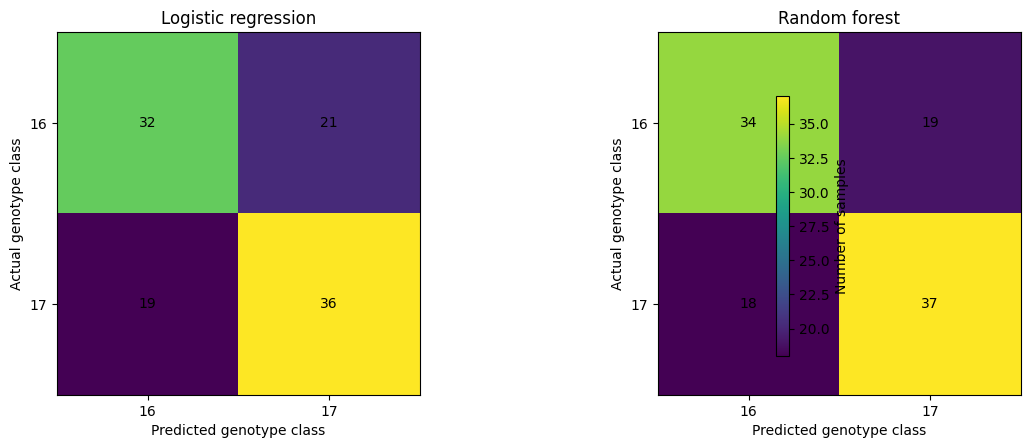

In [ ]:
import matplotlib.pyplot as plt

class_labels = sorted(y_test.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name, pred in [
    (axes[0], "Logistic regression", y_pred_logistic),
    (axes[1], "Random forest", y_pred_forest)
]:
    cm = confusion_matrix(y_test, pred, labels=class_labels)
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Predicted genotype class")
    ax.set_ylabel("Actual genotype class")
    ax.set_xticks(range(len(class_labels)), labels=class_labels)
    ax.set_yticks(range(len(class_labels)), labels=class_labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(image, ax=axes, shrink=0.75, label="Number of samples")
plt.tight_layout()
plt.show()

## 8. Compare performance and discuss results

Use the metrics and confusion matrices above to compare the models. The next cell identifies the model with the highest macro F1-score.

In [ ]:
best_model = results["Macro F1"].idxmax()
print("Model with the highest macro F1-score:", best_model)
display(results.round(4))

Model with the highest macro F1-score: Random forest


,Accuracy,Balanced accuracy,Macro F1
Model,,,
Random forest,0.6574,0.6571,0.6571
Logistic regression,0.6296,0.6292,0.6291


### My results and interpretation (complete after running) using the sample data

- The model with the highest accuracy was Random forest, with accuracy 0.6574.
- The model with the highest macro F1-score was Random forest, with macro F1 0.6571.
